In [1]:
# +----------------------------------------------------------------------------+
# |                                                                            |
# |       .-"""""""-.             ___                                          |
# |     .'           '.       _,~"                                             |
# |    /          .##.  \   ,~"                                                |
# |   |           '##'  |~"                                                    |
# |    \                /~,                                                    |
# |     '.            .'   "~,_                                                |
# |       '-........-'        "~,__                                            |
# |                                                                            |
# | Author    : Yatharth Bhasin (yatharth1997+ts@gmail.com)                    |
# | Date      : November 2026                                                  |
# | Copyright (c) 2026 Yatharth Bhasin                                         |
# | License-Identifier: MIT                                                    |
# +----------------------------------------------------------------------------+

# Fleet clock synchronization

How far apart are the scopes' clocks? A disturbance recorded on several scopes can only be lined up in time if
their clocks agree. This notebook puts a bound on the clock difference between any two scopes over one run. The
clocks are not made perfect; their error is measured.

*Analysis written by Claude (Anthropic); conceptualised and verified by Yatharth Bhasin.*

## Protocol

Acquisition: [`scripts/debug/fleet_clock_synchronization.py`](https://github.com/Trappy-Scopes/trappyscopes/blob/main/scripts/debug/fleet_clock_synchronization.py).
One NTP server gives time to every scope over the wired network. Each scope runs [chrony](https://chrony-project.org)
with that server as its only time source; `install_requirements()` sets this up once per scope. Each run then
logs what chrony measures for 2 h, and the runs on all scopes overlap. As in Lab Streaming Layer, clock offsets
are measured and stored next to the data, and the error is worked out afterwards.

Recommended: make sure the NTP server is itself well synchronized before the run.

**Running in Colab.** Open this notebook with the *Open in Colab* button on its page. The next cell runs only
in Colab: it installs what Colab lacks and asks for a `.zip` of your experiment folders.

In [2]:
import os, subprocess, sys
if "google.colab" in sys.modules:                         # skipped everywhere else
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "trappy-explorer @ git+https://github.com/Trappy-Scopes/trappy-explorer.git"], check=True)
    from google.colab import files
    for name in files.upload():                           # a .zip of your experiment folders
        subprocess.run(["unzip", "-q", "-o", name, "-d", "/content/data"], check=True)
    root = "/content/data"
    while True:                                           # step into a single wrapping folder
        subs = [d for d in os.listdir(root) if not d.startswith(("__MACOSX", "."))]
        if len(subs) == 1 and not os.path.exists(os.path.join(root, subs[0], "experiment.yaml")):
            root = os.path.join(root, subs[0])
        else:
            break
    os.environ["CALIBRATION_DATA"] = root

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
import rich, yaml
from explorer.legacy import ExpExplorer

DATA = os.environ.get("CALIBRATION_DATA", "/Users/byatharth/data/debugging/2026_11_16_fleet_clock_sync_test2")   # set to your own runs
OUT = "results"                                        # the fleet table is written here
TZ = "Europe/Lisbon"                                   # where the runs were recorded
ACCEPT_MS = 4.0                                        # largest allowed clock difference, two scopes
TICK_S = 10                                            # tracking_period_s of the script
SCOPES = [f"M{i}" for i in range(1, 9)]
ERR = {"server": "#2a78d6", "utc": "#eb6834", "limit": "#52514e"}
SERVER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]      # one per NTP server address
sns.set_theme(style="ticks", rc={"axes.grid": True, "grid.color": "#e8e8e6",
                                 "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                                 "lines.linewidth": 1.2, "legend.frameon": False})

## Data

Runs are read with trappy-explorer's legacy reader, `explorer.legacy.ExpExplorer`, in legacy mode: the script
writes plain numbers only, so nothing is dropped. Each run has four streams in `experiment.yaml`: `setup`
(what the clock follows, at the start and the end), `ntp` (one row per clock update from the NTP server),
`pico` (the Pico's clock, once a minute) and `tandh`.

In [4]:
rich.get_console().quiet = True                           # the loader prints one line per run
exps = ExpExplorer.create_superset(DATA)
rich.get_console().quiet = False
print(exps)

ms = exps.df_events.query("type == 'measurement_stream'")
res = exps.df.assign(stream=exps.df.measureid.map(dict(zip(ms.measureid, ms.name))),
                     wall=exps.df.machinetime / 1e9)    # the scope's own clock, as in tracking.csv
res.columns = res.columns.str.replace("nas_", "server_")  # older column names

setup = res[res.stream == "setup"].dropna(axis=1, how="all")
server_of = setup.sort_values("wall").drop_duplicates("eid").set_index("eid").server
runs = pd.DataFrame([{"scope": d["metadata"]["name"].split("__")[0], "eid": eid,
                      "started": d["metadata"]["created"], "server": server_of.get(eid)}
                     for eid, d in exps.data.items()]).set_index("scope").sort_index()
runs["hours"] = runs.eid.map(res.groupby("eid").wall.agg(lambda w: w.max() - w.min()) / 3600).round(2)
rows = res.groupby(["eid", "stream"]).size().unstack(fill_value=0)
runs = runs.join(rows.reindex(columns=["setup", "ntp", "pico", "tandh"], fill_value=0), on="eid")
present = [s for s in SCOPES if s in runs.index]
scope_of = runs.reset_index().set_index("eid").scope
runs

<Experiments :: 8  datasets>
  |- eid: fed3012801
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 69c7ae1ccc
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 67bace2a7f
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 2d3735125d
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: a3603baae8
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: a2188d631f
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 6511da1077
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico
  |- eid: 55240748de
  	|- m-stream: tandh
  	|- m-stream: setup
  	|- m-stream: ntp
  	|- m-stream: pico



,eid,started,server,hours,setup,ntp,pico,tandh
scope,,,,,,,,
M1,fed3012801,2026-11-16 11:21:01.050134,192.168.1.1,2.0,2,189,121,25
M2,2d3735125d,2026-11-16 11:21:19.660231,192.168.1.1,2.0,2,180,121,25
M3,a2188d631f,2026-11-16 11:21:40.818856,192.168.1.1,2.0,2,179,121,25
M4,67bace2a7f,2026-11-16 11:22:09.420776,192.168.1.1,2.0,2,189,121,25
M5,6511da1077,2026-11-16 11:23:34.628991,192.168.2.1,2.0,2,190,121,25
M6,69c7ae1ccc,2026-11-16 11:23:55.979675,192.168.2.1,2.0,2,180,120,24
M7,55240748de,2026-11-16 11:24:18.468048,192.168.2.1,2.0,2,163,121,25
M8,a3603baae8,2026-11-16 11:24:42.458747,192.168.2.1,2.0,2,178,121,25


In [5]:
eid = runs.eid.iloc[0]                                    # one run's folder, as an example
tree = exps.data[eid]["filetree"]["."]
print(os.path.basename(exps.get_parent_dir(eid)))
for f in sorted(tree["files"]) + sorted(k + "/" for k in tree if k != "files"):
    print("   ", f)

print()
skip = {"eid", "type", "measureid", "measureidx", "mid", "sid", "scriptid", "success", "dt",
        "exptime", "attribs", "machinetime", "sessiontime", "scopeid", "stream", "wall"}
for name, g in res.groupby("stream"):
    cols = [c for c in g.dropna(axis=1, how="all").columns if c not in skip]
    print(f"{name:6s} {len(g):5d} rows   {', '.join(cols)}")

M1__YB__2026_11_16__11hh_21mm__fleet_clock_sync__fed3012801
    chrony.conf
    experiment.yaml
    fed3012801_tracking.csv
    logs.yaml
    sessions.yaml
    analysis/
    converted/
    postprocess/
    scripts/

ntp     1448 rows   clock_offset_s, max_error_s, server_leap, server_stratum, offset_s, freq_ppm, leap, peer_delay_s, peer_dispersion_s, poll_s, root_delay_s, root_dispersion_s, server_root_delay_s, server_root_dispersion_s, skew_ppm
pico     967 rows   phase, error_s, offset_s, pico_time, wait_s, wire_s
setup     16 rows   chrony_active, chrony_version, clock_offset_s, iface, local_addr, max_error_s, n_sources, ntp_synchronized, phase, route_dev, rx_timestamping, server, server_leap, server_stratum, sign_check, sources, timesyncd
tandh    199 rows   humidity, temp


Each run folder also holds `<eid>_tracking.csv`: chrony's state every 10 s (`chronyc tracking`), taken on the
same wall-clock seconds on every scope, so rows from different scopes line up. Offsets are positive when the
scope's clock is ahead.

First, check that each run was set up as intended: one time source, reached over the cable, the old time
service off, and the offset sign confirmed on the scope (`sign_check`, expected `agree`). chrony's `ntpdata`
reports the offset with the opposite sign; runs recorded before the script flipped it (test 1, 2026-11-15) show
`OPPOSITE`, and their offsets are flipped below. `differ` means chrony had not yet used the last exchange.

In [6]:
checks = setup.assign(scope=setup.eid.map(scope_of))
checks[["scope", "phase", "server", "sources", "route_dev", "timesyncd", "ntp_synchronized",
        "rx_timestamping", "sign_check"]].sort_values(["scope", "phase"], ascending=[True, False]
                                                      ).set_index(["scope", "phase"])

server      sources route_dev timesyncd ntp_synchronized  \
scope phase                                                                  
M1    start  192.168.1.1  192.168.1.1      eth0  inactive              yes   
      end    192.168.1.1  192.168.1.1      eth0  inactive              yes   
M2    start  192.168.1.1  192.168.1.1      eth0  inactive              yes   
      end    192.168.1.1  192.168.1.1      eth0  inactive              yes   
M3    start  192.168.1.1  192.168.1.1      eth0  inactive              yes   
      end    192.168.1.1  192.168.1.1      eth0  inactive              yes   
M4    start  192.168.1.1  192.168.1.1      eth0  inactive              yes   
      end    192.168.1.1  192.168.1.1      eth0  inactive              yes   
M5    start  192.168.2.1  192.168.2.1      eth0  inactive              yes   
      end    192.168.2.1  192.168.2.1      eth0  inactive              yes   
M6    start  192.168.2.1  192.168.2.1      eth0  inactive              yes   
      end    192.168.2.1  192.168.2.1      eth0  inactive              yes   
M7    start  192.168.2.1  192.168.2.1      eth0  inactive              yes   
      end    192.168.2.1  192.168.2.1      eth0  inactive              yes   
M8    start  192.168.2.1  192.168.2.1      eth0  inactive              yes   
      end    192.168.2.1  192.168.2.1      eth0  inactive              yes   

            rx_timestamping                                     sign_check  
scope phase                                                                 
M1    start          Kernel  differ (ntpdata -0.000186, sources -0.000008)  
      end            Kernel                                          agree  
M2    start          Kernel                                          agree  
      end            Kernel  differ (ntpdata -0.000173, sources -0.000005)  
M3    start          Kernel  differ (ntpdata -0.000187, sources -0.000022)  
      end            Kernel                                          agree  
M4    start          Kernel  differ (ntpdata -0.000202, sources -0.000063)  
      end            Kernel                                          agree  
M5    start          Kernel  differ (ntpdata -0.000270, sources -0.000019)  
      end            Kernel                                          agree  
M6    start          Kernel  differ (ntpdata -0.000183, sources -0.000030)  
      end            Kernel                                          agree  
M7    start          Kernel                                          agree  
      end            Kernel                                          agree  
M8    start          Kernel                                          agree  
      end            Kernel                                          agree

## Maximum error

chrony bounds how far the scope's clock can be from true time (UTC):

    max error = |offset| + root dispersion + root delay / 2

Most of it is the NTP server's own distance from UTC, which is the same for every scope and cancels between
two scopes. The server's own root delay (`server_root_delay_s`) is removed. Its root dispersion is kept: chrony
reports the root dispersion of the sample it trusts most, often an older one, while the server's dispersion grows
between its own updates, so the latest `server_root_dispersion_s` is too large to subtract (in tests 1 and 2 that
gave a negative error 41-75% of the time). The error against the NTP server is then an upper bound, high by the
server's root dispersion (0.3-2.2 ms in tests 1 and 2):

    error to server = |offset| + root dispersion + (root delay - server root delay) / 2

In [7]:
ntp = res[res.stream == "ntp"].dropna(axis=1, how="all").copy()
old_sign = setup[setup.sign_check.astype(str).str.startswith("OPPOSITE")].eid.unique()
ntp.loc[ntp.eid.isin(old_sign), "offset_s"] *= -1        # recorded before the script fixed the sign
tr = pd.concat([pd.read_csv(f"{exps.get_parent_dir(e)}/{e}_tracking.csv").assign(eid=e)
                for e in runs.eid]).sort_values("wall")
last = ntp[["eid", "wall", "server_root_delay_s"]].sort_values("wall")
last["server_root_delay_s"] = last.groupby("eid").server_root_delay_s.cummin()  # never remove too much
tr = pd.merge_asof(tr, last, on="wall", by="eid", direction="backward")
tr["err_server_s"] = (tr.clock_offset_s.abs() + tr.root_dispersion_s
                      + (tr.root_delay_s - tr.server_root_delay_s) / 2)
tr = tr.dropna(subset=["err_server_s"])                  # before the run's first clock update
tr["scope"] = tr.eid.map(scope_of)
tr["time"] = pd.to_datetime(tr.wall, unit="s", utc=True).dt.tz_convert(TZ)

Each scope's maximum error over the run, against the NTP server (blue) and against UTC (orange). The dashed
line is the acceptable error for one scope, half of `ACCEPT_MS`: two scopes that both stay below it differ by
less than `ACCEPT_MS`. A slow ramp means the scope lost its NTP server for a while; a narrow peak is one slow
network exchange.

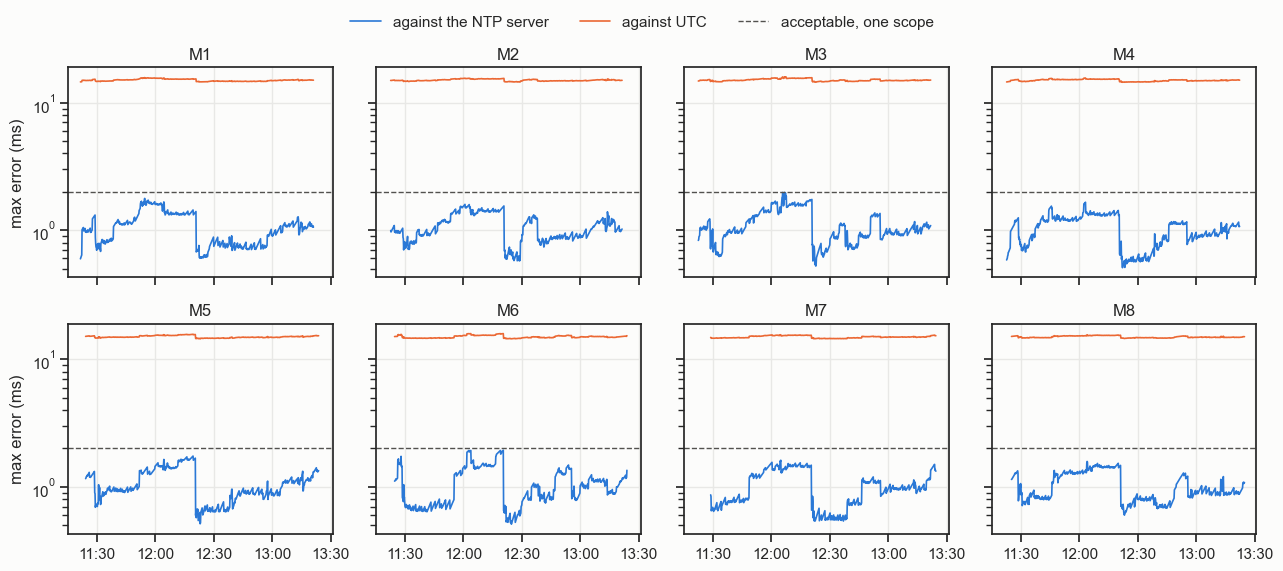

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, s in zip(axes.flat, SCOPES):
    d = tr[tr.scope == s]
    ax.plot(d.time, 1e3 * d.err_server_s, color=ERR["server"], label="against the NTP server")
    ax.plot(d.time, 1e3 * d.max_error_s, color=ERR["utc"], label="against UTC")
    ax.axhline(ACCEPT_MS / 2, color=ERR["limit"], ls="--", lw=1, label="acceptable, one scope")
    ax.set(yscale="log", title=s)
    ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30], tz=TZ))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
for ax in axes[:, 0]:
    ax.set_ylabel("max error (ms)")
handles = max((ax.get_legend_handles_labels() for ax in axes.flat), key=lambda h: len(h[0]))
fig.legend(*handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.05))
fig.tight_layout()

## Scope to scope

At every 10 s tick, two scopes' clocks differ by at most the sum of their errors against the NTP server. Over the
time all runs overlap, the map shows the value this bound stays below 99% of the time: the clocks of that pair
differed by less than this for 99% of the run. A dark row is a scope worse than the rest. This holds when every
server address belongs to the same NTP server, as here; otherwise compare against UTC instead.

shared window: 1.88 h, all 8 scopes


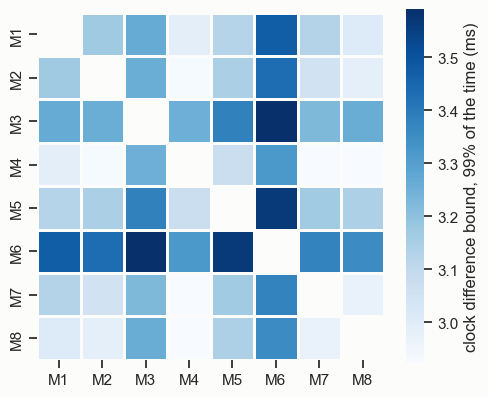

In [9]:
tr["tick"] = (tr.wall / TICK_S).round().astype(int)      # the shared grid
E = tr.pivot_table(index="tick", columns="scope", values="err_server_s")[present].dropna()
pair_p99 = pd.DataFrame({a: {b: np.percentile(E[a] + E[b], 99) if a != b else np.nan
                             for b in present} for a in present}).loc[present, present]
print(f"shared window: {len(E) * TICK_S / 3600:.2f} h, all {len(present)} scopes")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(1e3 * pair_p99, cmap="Blues", square=True, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "clock difference bound, 99% of the time (ms)"}, ax=ax)
ax.set(xlabel="", ylabel="")
ax.grid(False)

## Each NTP exchange

Every clock update: the offset measured to the NTP server, and the round-trip network delay to it, per scope and
coloured by server address. The delay shows the quality of each scope's network path; large offsets come from
slow exchanges.

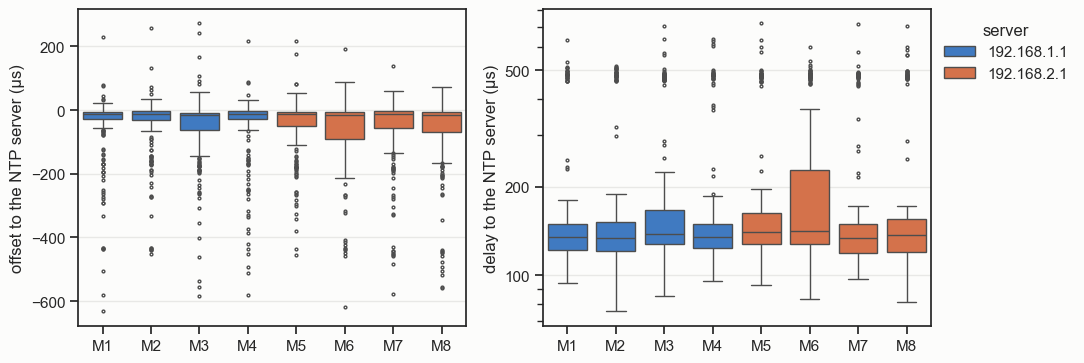

In [10]:
ntp = ntp.assign(scope=ntp.eid.map(scope_of), server=ntp.eid.map(server_of))
pal = dict(zip(sorted(ntp.server.unique()), SERVER_COLORS))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, label in zip(axes, ["offset_s", "peer_delay_s"],
                          ["offset to the NTP server (µs)", "delay to the NTP server (µs)"]):
    sns.boxplot(ntp.assign(v=1e6 * ntp[col]), x="scope", y="v", hue="server", order=present,
                hue_order=list(pal), palette=pal, fliersize=2, linewidth=1, ax=ax, legend=ax is axes[1])
    ax.set(xlabel="", ylabel=label)
axes[1].set_yscale("log")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1, 1), title="server")
axes[1].yaxis.set_major_locator(mticker.LogLocator(subs=(1.0, 2.0, 5.0)))
axes[1].yaxis.set_major_formatter(mticker.ScalarFormatter())
axes[1].yaxis.set_minor_formatter(mticker.NullFormatter())
fig.tight_layout()

## The Pico's clock

Each scope's Pico keeps its own clock, and nothing synchronizes it. The run reads it once a minute over the
serial link: as found for the first 5 min, then sets it once to the scope's time (UTC) and follows it. Each
reading is a request and reply timed to the moment the Pico's seconds tick over, with an error of a few ms
(`error_s`). This is for information and is not part of the acceptance. A Pico keeps its clock until it loses
power, so it is found either as set by an earlier run, or restarted at 2021-01-01.

As found: the Pico's clock at the start of the run, how far it was off (`found_s`, + = ahead), the board, and whether
its clock counts fractions of a second.

In [11]:
pico = res[res.stream == "pico"].dropna(axis=1, how="all").sort_values("wall")
pico["scope"] = pico.eid.map(scope_of)
info = exps.df_events.query("type == 'pico_check'").assign(scope=lambda d: d.eid.map(scope_of))
found = pico[pico.phase == "as_found"].groupby("scope").first()
found = info.set_index("scope")[["machine", "micropython", "time_ns_subsecond"]].join(
    found[["pico_time", "offset_s"]].rename(columns={"pico_time": "pico_clock_as_found"}))
found["found_s"] = found.pop("offset_s").round(3)
found.reindex(present).astype({"found_s": str})           # plain seconds, not 1.85e+08

,machine,micropython,time_ns_subsecond,pico_clock_as_found,found_s
scope,,,,,
M1,Raspberry Pi Pico W with RP2040,1.24.1,True,2026-11-16T11:21:11,0.831
M2,Raspberry Pi Pico W with RP2040,1.24.1,True,2026-11-16T11:21:31,0.734
M3,Raspberry Pi Pico W with RP2040,1.24.1,True,2026-11-16T11:21:51,0.721
M4,Raspberry Pi Pico W with RP2040,1.24.1,True,2026-11-16T11:22:21,0.523
M5,Raspberry Pi Pico W with RP2040,1.23.0,True,2021-01-01T19:52:09,-185297501.937
M6,Raspberry Pi Pico W with RP2040,1.24.0,True,2021-01-01T19:01:49,-185300541.376
M7,Raspberry Pi Pico W with RP2040,1.24.0,True,2026-11-16T11:24:31,0.738
M8,Raspberry Pi Pico W with RP2040,1.24.0,True,2026-11-16T11:24:51,0.76


After the set: how far each Pico's clock moved away from its scope's clock. The slope is the drift, in ppm (10 ppm
is 36 ms per hour). The orange band is how far apart two scopes' clocks can be (the worst pair in the map above,
99% of the time). The scopes stay inside it; the Picos leave it within minutes. The grey bar is the worst-case error of
one reading (median; half the serial round trip, so loose: the points scatter much less). A line that stops early is a Pico that stopped answering.

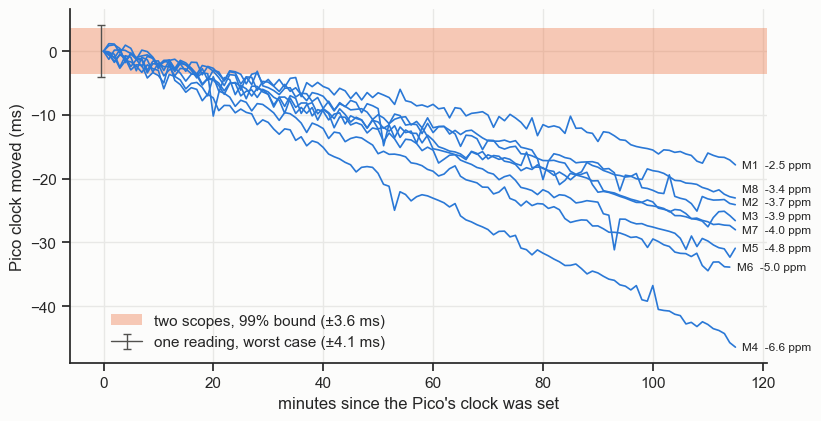

In [12]:
after = pico[pico.phase == "after_set"].copy()
t0 = after.groupby("scope").wall.transform("first")
after["minutes"] = (after.wall - t0) / 60
after["moved_ms"] = 1e3 * (after.offset_s - after.groupby("scope").offset_s.transform("first"))
drift = after.groupby("scope")[["wall", "offset_s"]].apply(
    lambda d: 1e6 * np.polyfit(d.wall - d.wall.iloc[0], d.offset_s, 1)[0])

band = 1e3 * pair_p99.max().max()
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.axhspan(-band, band, color=ERR["utc"], alpha=0.35, lw=0, label=f"two scopes, 99% bound (±{band:.1f} ms)")
ends = []
for s, d in after.groupby("scope"):
    ax.plot(d.minutes, d.moved_ms, color=ERR["server"], lw=1.2)
    ends.append([d.moved_ms.iloc[-1], d.minutes.iloc[-1], f"{s}  {drift[s]:+.1f} ppm"])
gap = 0.045 * np.ptp(after.moved_ms)                      # keep the end labels apart
ends.sort()
for i in range(1, len(ends)):
    ends[i][0] = max(ends[i][0], ends[i - 1][0] + gap)
for y, x, label in ends:
    ax.annotate(label, (x, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=8.5)
e = 1e3 * after.error_s.median()
ax.errorbar(-0.4, 0, yerr=e, color=ERR["limit"], capsize=3, lw=1, label=f"one reading, worst case (±{e:.1f} ms)")
ax.set(xlabel="minutes since the Pico's clock was set", ylabel="Pico clock moved (ms)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0.04, 0));

## Results

One row per scope. `err_*_ms` is the error against the NTP server (the upper bound above); `utc_p99_ms` is chrony's own bound against
UTC; `worst_pair_p99_ms` is the scope's largest value in the map above; `longest_gap_s` is the longest time
between two clock updates. `pico_*`: how far off the Pico's clock was as found (s, + = ahead), its offset right after
it was set (ms; about +1000 ms in test 1, before the script wrote the time one second early), its drift (ppm) and how far it moved after the set (ms).

In [13]:
q = lambda p: (lambda x: 1e3 * x.quantile(p))
fleet = runs[["eid", "server"]].join(tr.groupby("scope").agg(
    err_p50_ms=("err_server_s", q(0.5)), err_p99_ms=("err_server_s", q(0.99)),
    err_max_ms=("err_server_s", q(1.0)), utc_p99_ms=("max_error_s", q(0.99))))
fleet["delay_p50_us"] = 1e6 * ntp.groupby("scope").peer_delay_s.median()
fleet["offset_p99_us"] = 1e6 * ntp.groupby("scope").offset_s.apply(lambda x: x.abs().quantile(0.99))
fleet["longest_gap_s"] = ntp.sort_values("wall").groupby("scope").wall.apply(lambda w: w.diff().max())
fleet["worst_pair_p99_ms"] = 1e3 * pair_p99.max()
fleet["pico_found_s"] = found.found_s
fleet["pico_set_ms"] = 1e3 * after.groupby("scope").offset_s.first()
fleet["pico_drift_ppm"] = drift
fleet["pico_moved_max_ms"] = after.groupby("scope").moved_ms.apply(lambda x: x.abs().max())
fleet["accepted"] = fleet.worst_pair_p99_ms < ACCEPT_MS
fleet = fleet.reindex(present)

os.makedirs(OUT, exist_ok=True)
fleet.to_csv(f"{OUT}/fleet_clock_synchronization.csv")
for s, row in fleet.iterrows():                           # one copy next to each run's data
    os.makedirs(exps.get_analysis_dir(row.eid), exist_ok=True)
    with open(os.path.join(exps.get_analysis_dir(row.eid), "fleet_clock_synchronization.yaml"), "w") as f:
        yaml.safe_dump({k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}, f)
fleet.round(3).astype({"pico_found_s": str})

,eid,server,err_p50_ms,err_p99_ms,err_max_ms,utc_p99_ms,delay_p50_us,offset_p99_us,longest_gap_s,worst_pair_p99_ms,pico_found_s,pico_set_ms,pico_drift_ppm,pico_moved_max_ms,accepted
scope,,,,,,,,,,,,,,,
M1,fed3012801,192.168.1.1,1.027,1.677,1.777,15.654,134.911,513.064,159.998,3.472,0.831,-0.496,-2.469,17.833,True
M2,2d3735125d,192.168.1.1,1.003,1.557,1.595,15.534,134.182,437.992,180.002,3.431,0.734,-0.280,-3.667,25.086,True
M3,a2188d631f,192.168.1.1,1.003,1.824,1.981,15.801,138.451,540.259,190.000,3.591,0.721,-0.702,-3.917,27.547,True
M4,67bace2a7f,192.168.1.1,1.067,1.531,1.658,15.508,134.629,494.305,160.002,3.320,0.523,-1.509,-6.600,46.418,True
M5,6511da1077,192.168.2.1,0.966,1.694,1.742,15.671,140.284,386.868,159.996,3.565,-185297501.937,-0.136,-4.844,32.312,True
M6,69c7ae1ccc,192.168.2.1,0.994,1.915,1.934,15.892,141.810,451.361,130.004,3.591,-185300541.376,-1.031,-4.971,34.440,True
M7,55240748de,192.168.2.1,0.970,1.532,1.616,15.509,134.220,467.410,199.998,3.379,0.738,-0.501,-4.006,28.013,True
M8,a3603baae8,192.168.2.1,0.909,1.506,1.580,15.483,137.603,527.676,170.002,3.355,0.76,-0.813,-3.385,23.022,True


## Acceptance

Two scopes are accepted when their clock difference bound stays below `ACCEPT_MS` = 4 ms for 99% of the shared
window. 4 ms is a tenth of one frame at 25 fps, so a disturbance seen on two scopes falls in the same frame. The
fleet passes when every pair does.

In [14]:
pairs = pair_p99.stack()
a, b = pairs.idxmax()
print(f"worst pair {a}-{b}: {1e3 * pairs.max():.3f} ms (limit {ACCEPT_MS} ms)")
print("fleet:", "PASS" if (1e3 * pairs < ACCEPT_MS).all() else "FAIL")

worst pair M3-M6: 3.591 ms (limit 4.0 ms)
fleet: PASS


## Persistent records

This calibration writes 0 records to the scope. Its set-up step, `install_requirements()`, does change the
scope's time service: chrony replaces systemd-timesyncd, with the NTP server as its only source. The run also
sets each Pico's clock to UTC once; the Pico loses that setting when it loses power.